# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 1 (versión multi-cuento): Exploración, partición y modelo baseline
### Predicción del siguiente carácter sobre varios cuentos de H. P. Lovecraft

**Estudiantes:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini  
**Docente:** Pablo Moreira  

---
### Qué cambia respecto de la versión con un solo cuento
La versión anterior usaba solo *The Festival* (~20.000 caracteres). Allí, el 52 % de los errores de una muestra eran 5-gramas que no aparecían en Train, y el MLP tenía una brecha Train–Dev de 20 a 24 pp (varianza alta). Las dos señales apuntan a que faltan datos. Esta versión usa **varios cuentos** y cambia la estrategia de partición:

| Conjunto | De dónde sale | Cómo se arma |
|---|---|---|
| **Train y Dev** | Bloques de **todos** los cuentos no reservados | Cada cuento se corta en bloques de ~400 caracteres y cada bloque se asigna a Train o Dev. Así los dos conjuntos cubren distintas partes de todos los cuentos. |
| **Test** | **Cuentos completos reservados**, que no participan en Train ni en Dev | Ninguna parte de esos cuentos se usa para entrenar ni para elegir hiperparámetros. |

### Decisiones generales
1. **Limpieza reproducible dentro del notebook**, aplicada igual a cada cuento.
2. **Bloques contiguos** para Train/Dev: dos ventanas vecinas comparten 39 de sus 40 caracteres, así que un reparto aleatorio de ventanas filtraría información de Train a Dev.
3. **Test = cuentos enteros sin tocar.** Evita la fuga por solapamiento y además mide generalización a un texto nuevo. Esto incluye un posible *data mismatch* entre cuentos, que diagnosticamos en el EDA.
4. **Vocabulario fijo** calculado sobre la unión de los cuentos (es solo el alfabeto, no usa ninguna etiqueta).
5. **Métricas:** accuracy top-1 en Dev (número único de la consigna) y, como complemento, la perplejidad, que es la medida natural para un generador.
6. **Baseline:** regresión logística sobre el one-hot de los últimos $K$ caracteres.
7. **Los resultados no son comparables con los de la versión de un solo cuento**: cambian Train, Dev y Test. El baseline se vuelve a medir acá.

In [80]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os, re, json, time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# ------------------------- PARÁMETROS DEL EXPERIMENTO -------------------------
SEED = 42
L = 40                 # longitud de la ventana de contexto
BLOQUE = 400           # caracteres por bloque (Train/Dev)
FRAC_TEST = 0.10     # fracción aproximada del corpus (en caracteres) reservada para Test
FRAC_DEV = 0.10       # fracción de los bloques de cada cuento que va a Dev
# Cuentos reservados para Test, por nombre de archivo sin ".txt" (ej.: ["The_Outsider"]).
# Si queda vacío, se eligen automáticamente con la semilla, hasta cubrir ~FRAC_TEST del corpus.
TEST_STORIES = []
EPS = 1e-6             # piso de probabilidad para la pérdida (se usa igual para todos los modelos)

np.random.seed(SEED)
print("Entorno y bibliotecas configurados correctamente.")

Entorno y bibliotecas configurados correctamente.


---
# 1. Consigna 4.1.1: Carga y Análisis Exploratorio del Dataset (EDA)

## 1.1 Carga de los cuentos y limpieza
Se leen **todos los `.txt` de la carpeta `db/`** (un archivo por cuento). A cada uno se le aplican las mismas transformaciones mínimas:

| Paso | Transformación | Justificación |
|---|---|---|
| 0. Cabecera/licencia | Se recorta lo que está fuera de los marcadores `*** START OF ... ***` y `*** END OF ... ***` de Project Gutenberg, si existen | Son metadatos y licencia, no texto literario. |
| 1. Fin de línea | `CRLF` $\to$ `LF` | Estandariza los saltos de línea. |
| 2. Etiquetas HTML | Se eliminan `<i>` y `</i>` | Maquetación tipográfica. |
| 3. Tipografía | Comillas y apóstrofos curvos $\to$ rectos | Normaliza variantes idénticas. |
| 4. Espaciado | Múltiples espacios/saltos $\to$ un espacio | Los saltos forzados por formato agregarían ruido arbitrario a las ventanas de 40 caracteres. |

In [81]:
# ==============================================================================
# CARGA DE LOS CUENTOS (un .txt por cuento en la carpeta db/)
# ==============================================================================
def encontrar_base():
    cwd = Path.cwd()
    for cand in [cwd, cwd.parent, cwd / "ia-generacion-caracteres" / "ia-generacion-caracteres"]:
        if (cand / "db").exists():
            return cand
    return cwd

BASE_DIR = encontrar_base()
STORIES_DIR = BASE_DIR / "db"
archivos = sorted(STORIES_DIR.glob("*.txt")) if STORIES_DIR.exists() else []
if not archivos:
    raise FileNotFoundError(f"No se encontraron archivos .txt en {STORIES_DIR}. Colocá allí un .txt por cuento.")

# Todas las salidas van a una carpeta propia (no pisan los archivos de la versión de un solo cuento)
OUT_DIR = BASE_DIR / "data" / "processed_multi"
OUT_DIR.mkdir(parents=True, exist_ok=True)

crudos = {p.stem: p.read_text(encoding="utf-8") for p in archivos}
print(f"{len(crudos)} cuentos encontrados en {STORIES_DIR.name}/:")
for n, t in crudos.items():
    print(f"  • {n}: {len(t):,} caracteres leídos")

2 cuentos encontrados en db/:
  • The callof cthulhu: 70,120 caracteres leídos
  • The_Festival: 20,190 caracteres leídos


In [82]:
# ==============================================================================
# LIMPIEZA PASO A PASO (la misma para todos los cuentos)
# ==============================================================================
def quitar_cabecera_gutenberg(t):
    ini = re.search(r"\*\*\* ?START OF[^\n]*\*\*\*", t, flags=re.I)
    if ini:
        t = t[ini.end():]
    fin = re.search(r"\*\*\* ?END OF[^\n]*\*\*\*", t, flags=re.I)
    if fin:
        t = t[:fin.start()]
    return t

pasos = [
    ("0. Quitar cabecera/licencia", quitar_cabecera_gutenberg),
    ("1. CRLF -> LF", lambda t: t.replace("\r\n", "\n").replace("\r", "\n")),
    ("2. Quitar <i> y </i>", lambda t: re.sub(r"</?i>", "", t)),
    ("3. Comillas curvas a rectas", lambda t: t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')),
    ("4. Estandarizar espacios y saltos", lambda t: re.sub(r"\s+", " ", t).strip()),
]

stories, registro = {}, []
for nombre, t in crudos.items():
    n_orig, v_orig = len(t), len(set(t))
    for _, fn in pasos:
        t = fn(t)
    stories[nombre] = t
    registro.append({"Cuento": nombre, "Caracteres originales": n_orig, "Caracteres limpios": len(t),
                     "|V| original": v_orig, "|V| limpio": len(set(t))})

df_limpieza = pd.DataFrame(registro).set_index("Cuento")
print(df_limpieza.to_string())

for n, t in stories.items():
    if len(t) < 2 * BLOQUE:
        warnings.warn(f"'{n}' tiene solo {len(t)} caracteres: es muy corto para partirlo en bloques.")
    if re.search(r"gutenberg", t[:300] + t[-300:], flags=re.I):
        warnings.warn(f"'{n}' parece conservar texto de cabecera/licencia de Gutenberg. Revisalo.")
print(f"\nInicio de cada cuento limpio:")
for n, t in stories.items():
    print(f"  {n}: {t[:70]!r}")

                    Caracteres originales  Caracteres limpios  |V| original  |V| limpio
Cuento                                                                                 
The callof cthulhu                  70120               69904            80          79
The_Festival                        20190               20180            69          64

Inicio de cada cuento limpio:
  The callof cthulhu: 'The CALL of CTHULHU By H.P. LOVECRAFT "Of such great powers or beings '
  The_Festival: 'I was far from home, and the spell of the eastern sea was upon me. In '


## 1.2 Descripción de las variables
| Variable | Rol | Tipo de dato | Dominio / Rango |
|---|---|---|---|
| `X` | Contexto de entrada | Secuencia de caracteres | Cadena de longitud fija $L = 40$ |
| `y` | Carácter objetivo (clase) | Categórica nominal | Un carácter del vocabulario $|V|$ |
| `cuento` | Metadato (no es entrada del modelo) | Categórica nominal | Cuento de origen de la ventana; sirve para auditar la partición |

**Valores nulos:** $0$. Cada posición del texto tiene un carácter válido.

In [83]:
# ==============================================================================
# ESTADÍSTICAS BÁSICAS DEL CORPUS
# ==============================================================================
corpus_total = "".join(stories.values())
vocabulary = sorted(set(corpus_total))
vocab_size = len(vocabulary)
char_counts = Counter(corpus_total)
serie = pd.Series(char_counts).sort_values(ascending=False)

def palabras_de(t): return re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", t)

filas = []
for n, t in stories.items():
    w = palabras_de(t)
    filas.append({"Cuento": n, "Caracteres": len(t), "Palabras": len(w),
                  "Palabras distintas": len({x.lower() for x in w}),
                  "Oraciones (aprox.)": len([s for s in re.split(r"[.!?]+", t) if s.strip()]),
                  "|V|": len(set(t))})
df_cuentos = pd.DataFrame(filas).set_index("Cuento")
df_cuentos.loc["TOTAL"] = [len(corpus_total), df_cuentos["Palabras"].sum(), len({x.lower() for x in palabras_de(corpus_total)}),
                           df_cuentos["Oraciones (aprox.)"].sum(), vocab_size]
print(df_cuentos.to_string())
print(f"\nVocabulario del corpus ({vocab_size} caracteres):\n{''.join(vocabulary)!r}")
print("Valores nulos: 0")

                    Caracteres  Palabras  Palabras distintas  Oraciones (aprox.)  |V|
Cuento                                                                               
The callof cthulhu       69904     11863                3137                 465   79
The_Festival             20180      3578                1240                 119   64
TOTAL                    90084     15441                3780                 584   80

Vocabulario del corpus (80 caracteres):
' !"&\'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWYZ_abcdefghijklmnopqrstuvwxyz°´é—'
Valores nulos: 0


### Gráfico 1: Tamaño de cada cuento
El tamaño importa por dos motivos: define cuántos bloques aporta cada cuento a Train/Dev y cuánto pesa cada texto reservado para Test.

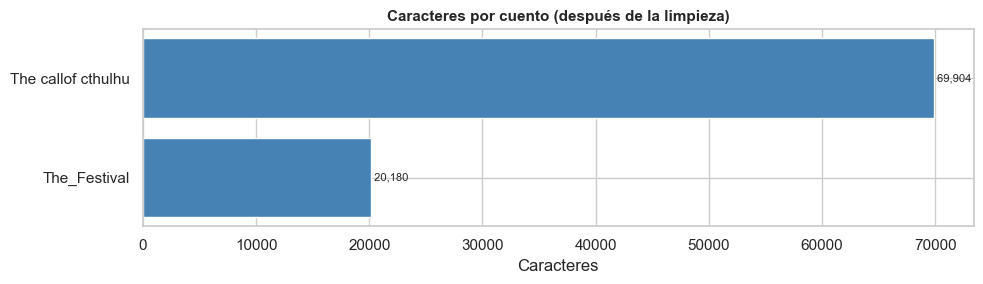

In [84]:
fig, ax = plt.subplots(figsize=(10, max(3, 0.4 * len(stories) + 1)))
tam = df_cuentos.drop("TOTAL")["Caracteres"].sort_values()
ax.barh(tam.index, tam.values, color="steelblue")
for i, v in enumerate(tam.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
ax.set_title("Caracteres por cuento (después de la limpieza)", fontsize=11, fontweight="bold")
ax.set_xlabel("Caracteres")
plt.tight_layout(); plt.show()

### Gráfico 2: Distribución de frecuencia de caracteres (desbalance de clases)
Cada carácter es una clase. Comparamos los 20 más frecuentes con los 20 menos frecuentes de todo el corpus.

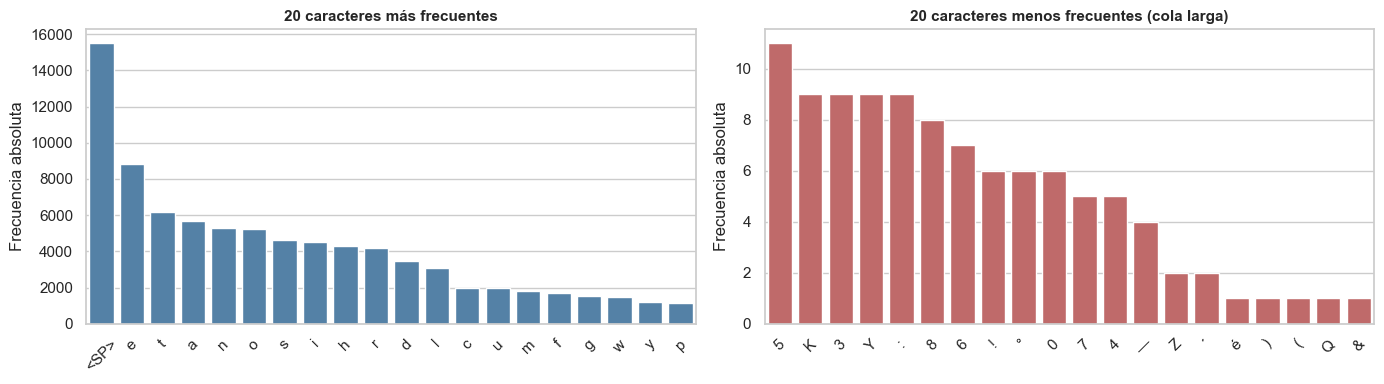

In [85]:
def vis(c):
    return {" ": "<SP>", "\n": "<NL>"}.get(str(c), str(c))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
top20 = serie.head(20)
sns.barplot(x=[vis(c) for c in top20.index], y=top20.values, ax=axes[0], color="steelblue")
axes[0].set_title("20 caracteres más frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta"); axes[0].tick_params(axis="x", rotation=45)
bottom20 = serie.tail(20)
sns.barplot(x=[vis(c) for c in bottom20.index], y=bottom20.values, ax=axes[1], color="indianred")
axes[1].set_title("20 caracteres menos frecuentes (cola larga)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Gráfico 3: Longitud de palabras por cuento
Muestra si el estilo léxico (largo de palabras) es parecido entre cuentos.

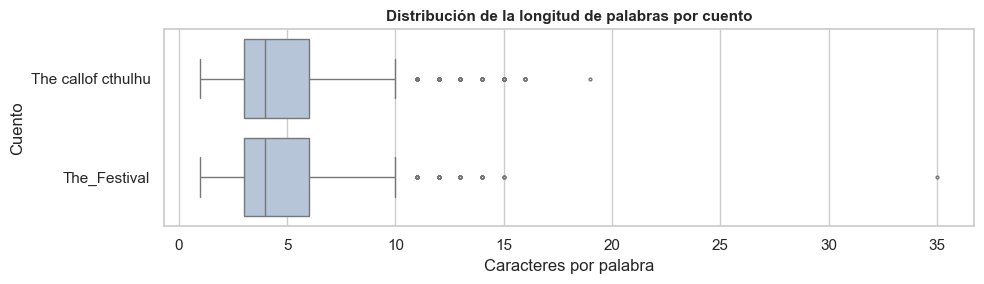

Palabras más largas del corpus: ['great-great-great-great-grandfather', 'commonplace-looking', 'nautical-looking', "vice-admiralty's", 'monolith-crowned', 'fellow-prisoners']


In [86]:
filas = [(n, len(w)) for n, t in stories.items() for w in palabras_de(t)]
df_pl = pd.DataFrame(filas, columns=["Cuento", "Largo"])
fig, ax = plt.subplots(figsize=(10, max(3, 0.4 * len(stories) + 1)))
sns.boxplot(data=df_pl, y="Cuento", x="Largo", ax=ax, color="lightsteelblue", fliersize=2)
ax.set_title("Distribución de la longitud de palabras por cuento", fontsize=11, fontweight="bold")
ax.set_xlabel("Caracteres por palabra")
plt.tight_layout(); plt.show()
largas = sorted({w for t in stories.values() for w in palabras_de(t) if len(w) >= 14}, key=len, reverse=True)
print("Palabras más largas del corpus:", largas[:6])

### Gráfico 4: Signos de puntuación por cuento (cada 1.000 caracteres)
Normalizamos por 1.000 caracteres para poder comparar cuentos de distinto tamaño.

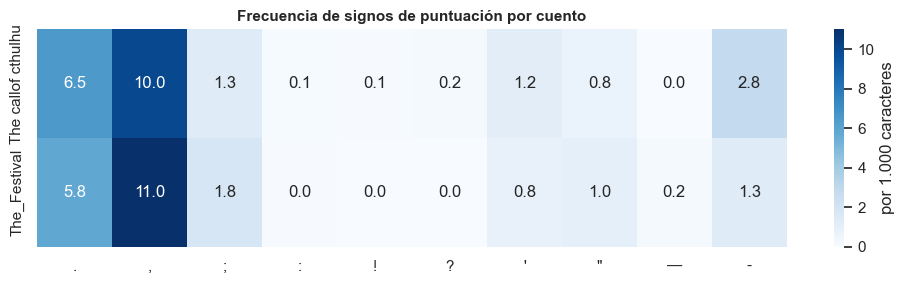

In [87]:
signos = list(".,;:!?'\"—-")
mat = pd.DataFrame({n: [t.count(s) / len(t) * 1000 for s in signos] for n, t in stories.items()}, index=signos).T
plt.figure(figsize=(10, max(3, 0.4 * len(stories) + 1)))
sns.heatmap(mat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "por 1.000 caracteres"})
plt.title("Frecuencia de signos de puntuación por cuento", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### Diagnóstico de problemas potenciales: desbalance, outliers y *data mismatch*
1. **Desbalance de clases:** el espacio y algunas vocales dominan el texto.
2. **Clases raras (outliers):** caracteres con menos de 10 apariciones en todo el corpus.
3. ***Data mismatch* entre cuentos:** como Test son cuentos distintos de los de Train/Dev, medimos cuánto se parecen las distribuciones de caracteres entre cuentos con la **divergencia de Jensen–Shannon** (0 = idénticas; 1 = disjuntas, usando $\log_2$). Es una referencia: cuanto mayor, más se parecen los errores en Test a un problema de distribución y menos a uno de modelo.

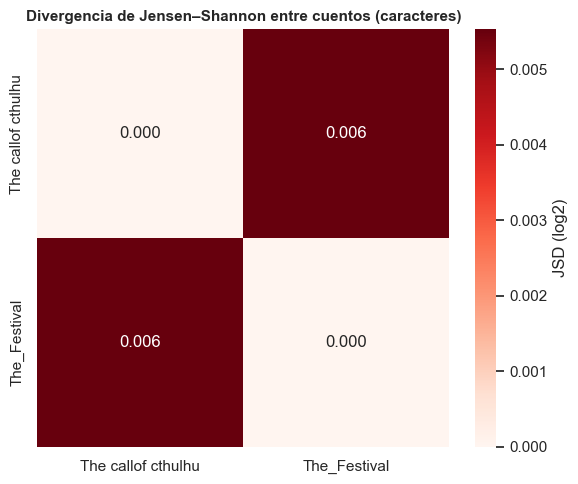

DIAGNÓSTICO DEL DATASET:
  • Desbalance: la clase mayoritaria '<SP>' representa el 17.2% del corpus; '&' aparece solo 1 vez/veces.
  • Clases raras: 19 de 80 caracteres tienen menos de 10 apariciones: ['!', '&', '(', ')', '0', '3', '4', '6', '7', '8', ':', 'K', 'Q', 'Y', 'Z', '°', '´', 'é', '—']
  • Data mismatch entre cuentos: JSD medio = 0.0055, máximo = 0.0055. (Referencia: si los valores son < 0.02 el vocabulario de caracteres es casi idéntico entre cuentos.)


In [88]:
def dist_chars(t):
    v = np.array([Counter(t)[c] for c in vocabulary], dtype=float)
    return v / v.sum()

def jsd(p, q):
    m = (p + q) / 2
    kl = lambda a, b: np.sum(a[a > 0] * np.log2(a[a > 0] / b[a > 0]))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

nombres = list(stories)
P = {n: dist_chars(t) for n, t in stories.items()}
M = pd.DataFrame([[jsd(P[a], P[b]) for b in nombres] for a in nombres], index=nombres, columns=nombres)

plt.figure(figsize=(max(6, 0.7 * len(nombres) + 2), max(5, 0.6 * len(nombres) + 2)))
sns.heatmap(M, annot=len(nombres) <= 10, fmt=".3f", cmap="Reds", vmin=0, cbar_kws={"label": "JSD (log2)"})
plt.title("Divergencia de Jensen–Shannon entre cuentos (caracteres)", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

raros = [c for c, n in char_counts.items() if n < 10]
tri = M.values[np.triu_indices(len(nombres), k=1)]
print("DIAGNÓSTICO DEL DATASET:")
print(f"  • Desbalance: la clase mayoritaria '{vis(serie.index[0])}' representa el {serie.iloc[0]/len(corpus_total)*100:.1f}% del corpus; "
      f"'{vis(serie.index[-1])}' aparece solo {serie.iloc[-1]} vez/veces.")
print(f"  • Clases raras: {len(raros)} de {vocab_size} caracteres tienen menos de 10 apariciones: {sorted(vis(c) for c in raros)}")
if len(tri):
    print(f"  • Data mismatch entre cuentos: JSD medio = {tri.mean():.4f}, máximo = {tri.max():.4f}. "
          f"(Referencia: si los valores son < 0.02 el vocabulario de caracteres es casi idéntico entre cuentos.)")

---
# 2. Consigna 4.1.2: Partición de datos (Train / Dev / Test)

## 2.1 Estrategia
1. **Test: cuentos completos reservados.** Se eligen antes de mirar cualquier resultado (ver `TEST_STORIES` en la configuración; si está vacío se eligen con la semilla hasta cubrir ~15 % del corpus) y **no se usan para entrenar, ni para elegir hiperparámetros, ni para decidir qué modelo es mejor**. Solo calculamos las proporciones de clases para verificar la partición.
2. **Train y Dev: bloques de todos los cuentos restantes.** Cada cuento se corta en bloques de ~400 caracteres. Dentro de cada cuento, un 15 % de los bloques (elegidos al azar con semilla fija) va a Dev y el resto a Train. Así **cada cuento está representado en los dos conjuntos** y Dev cubre distintas partes de la historia.
3. Las ventanas de 40 caracteres se generan **solo dentro de cada bloque**, para que ninguna cruce el límite entre Train y Dev.
4. Verificamos que no haya texto repetido entre Train/Dev y los cuentos de Test (por ejemplo, el mismo cuento en dos archivos o pasajes copiados).

In [89]:
# ==============================================================================
# SELECCIÓN DE CUENTOS DE TEST Y PARTICIÓN POR BLOQUES
# ==============================================================================
total_chars = sum(len(t) for t in stories.values())

if TEST_STORIES:
    faltan = [n for n in TEST_STORIES if n not in stories]
    assert not faltan, f"TEST_STORIES contiene nombres que no existen en db/: {faltan}"
    test_names = list(TEST_STORIES)
else:
    rng_sel = np.random.default_rng(SEED)
    test_names, acum = [], 0
    for n in rng_sel.permutation(list(stories)):
        if acum >= FRAC_TEST * total_chars:
            break
        if len(stories) - len(test_names) <= 2:     # dejar al menos 2 cuentos para Train/Dev
            break
        test_names.append(str(n)); acum += len(stories[str(n)])
trdev_names = [n for n in stories if n not in test_names]
print("TEST_STORIES:", TEST_STORIES)
print("FRAC_TEST:", FRAC_TEST)
print("L:", L)
print("Total de cuentos:", len(stories))
print("Cuentos seleccionados para Test:", test_names)

for n in test_names:
    print(f"  {n}: {len(stories[n])} caracteres")
#assert test_names and trdev_names, "Hacen falta al menos 1 cuento de Test y 1 de Train/Dev."

def limites_de(n_chars):
    lim = [(i, min(i + BLOQUE, n_chars)) for i in range(0, n_chars, BLOQUE)]
    if len(lim) >= 2 and lim[-1][1] - lim[-1][0] < BLOQUE // 2:
        ini_prev = lim[-2][0]
        lim = lim[:-2] + [(ini_prev, n_chars)]
    return lim

limites, bloques = {}, {"train": {}, "dev": {}}
for k, n in enumerate(trdev_names):
    lim = limites_de(len(stories[n]))
    orden = np.random.default_rng(SEED + k).permutation(len(lim))
    n_dev = max(1, round(FRAC_DEV * len(lim))) if len(lim) >= 2 else 0
    limites[n] = lim
    bloques["dev"][n] = sorted(orden[:n_dev].tolist())
    bloques["train"][n] = sorted(orden[n_dev:].tolist())

def ventanas_bloques(split):
    X, y, src = [], [], []
    for n, ids in bloques[split].items():
        t = stories[n]
        for b in ids:
            ini, fin = limites[n][b]
            for i in range(ini, fin - L):
                X.append(t[i:i + L]); y.append(t[i + L]); src.append(n)
    return X, y, src

def ventanas_cuento_completo(nombres_):
    X, y, src = [], [], []
    for n in nombres_:
        t = stories[n]
        for i in range(len(t) - L):
            X.append(t[i:i + L]); y.append(t[i + L]); src.append(n)
    return X, y, src

X_train, y_train, s_train = ventanas_bloques("train")
X_dev,   y_dev,   s_dev   = ventanas_bloques("dev")
X_test,  y_test,  s_test  = ventanas_cuento_completo(test_names)

n_total = len(X_train) + len(X_dev) + len(X_test)
print(f"CUENTOS DE TEST (reservados enteros): {test_names}")
print(f"CUENTOS PARA TRAIN/DEV ({len(trdev_names)}): {trdev_names}\n")
print(f"  • Train: {len(X_train):>8,} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>8,} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>8,} muestras ({len(X_test)/n_total*100:4.1f}%)")
print(f"\nEjemplo:\n  Contexto X: {X_train[0]!r}\n  Objetivo y: {y_train[0]!r}")
assert test_names, "No se seleccionaron cuentos para Test."
assert all(len(stories[n]) > L for n in test_names), \
    "Hay cuentos de Test demasiado cortos para generar ventanas."

TEST_STORIES: []
FRAC_TEST: 0.1
L: 40
Total de cuentos: 2
Cuentos seleccionados para Test: []
CUENTOS DE TEST (reservados enteros): []
CUENTOS PARA TRAIN/DEV (2): ['The callof cthulhu', 'The_Festival']

  • Train:   72,804 muestras (89.8%)
  • Dev:      8,280 muestras (10.2%)
  • Test:         0 muestras ( 0.0%)

Ejemplo:
  Contexto X: 'The CALL of CTHULHU By H.P. LOVECRAFT "O'
  Objetivo y: 'f'


AssertionError: No se seleccionaron cuentos para Test.

## 2.2 Auditoría de la partición
Tabla de muestras por cuento y conjunto: cada cuento de Train/Dev debería aparecer en **ambos**, y los cuentos de Test, solo en Test.

In [ ]:
cnt = pd.DataFrame({"Train": pd.Series(Counter(s_train)), "Dev": pd.Series(Counter(s_dev)),
                    "Test": pd.Series(Counter(s_test))}).fillna(0).astype(int)
cnt["Total"] = cnt.sum(axis=1)
cnt["Rol"] = ["TEST (reservado)" if n in test_names else "Train/Dev" for n in cnt.index]
print(cnt.to_string())
assert all(cnt.loc[n, "Train"] == 0 and cnt.loc[n, "Dev"] == 0 for n in test_names), "Un cuento de Test aparece en Train/Dev."
assert all(cnt.loc[n, "Test"] == 0 for n in trdev_names), "Un cuento de Train/Dev aparece en Test."
print("\nOK: los cuentos de Test no aparecen en Train ni en Dev.")

                    Train   Dev   Test  Total               Rol
The callof cthulhu  56424  6480      0  62904         Train/Dev
The_Festival            0     0  20140  20140  TEST (reservado)

OK: los cuentos de Test no aparecen en Train ni en Dev.


## 2.3 Verificación anti-fuga: texto repetido entre Test y Train/Dev
Buscamos fragmentos de 50 caracteres de los cuentos de Test que también aparezcan en los cuentos de Train/Dev. Un número alto indicaría un cuento duplicado o una cita larga. Unas pocas coincidencias aisladas (frases hechas) son esperables.

In [ ]:
SH = 50
def shingles(t): return {t[i:i + SH] for i in range(len(t) - SH + 1)}
sh_test = set().union(*[shingles(stories[n]) for n in test_names])

filas = []
for n in trdev_names:
    t = stories[n]
    coinc = sum(1 for i in range(len(t) - SH + 1) if t[i:i + SH] in sh_test)
    filas.append({"Cuento Train/Dev": n, "Posiciones": len(t) - SH + 1, "Coinciden con Test": coinc,
                  "%": round(coinc / max(1, len(t) - SH + 1) * 100, 2)})
df_fuga = pd.DataFrame(filas).set_index("Cuento Train/Dev")
print(df_fuga.to_string())
sospechosos = df_fuga[df_fuga["%"] > 5].index.tolist()
print("\n" + ("ATENCIÓN: revisar posibles duplicados con Test: " + str(sospechosos) if sospechosos
              else "Sin duplicados evidentes entre Test y Train/Dev."))

                    Posiciones  Coinciden con Test    %
Cuento Train/Dev                                       
The callof cthulhu       69855                   0  0.0

Sin duplicados evidentes entre Test y Train/Dev.


In [ ]:
print("Tamaño de vocabulary:", len(vocabulary))
print("Ejemplos de vocabulary:", list(vocabulary)[:15])
conteos = {"Train": Counter(y_train), "Dev": Counter(y_dev), "Test": Counter(y_test)}
freq = pd.DataFrame({s: pd.Series(c).reindex(vocabulary, fill_value=0) for s, c in conteos.items()})

print("\nConteos:")
for nombre, c in conteos.items():
    print(f"{nombre}:")
    print("  Total:", sum(c.values()))
    print("  Primeros valores:", c.most_common(10))

print("\nSuma de columnas de freq:")
print(freq.sum())

print("\nDimensiones de freq:", freq.shape)

print("X_test:", len(X_test))
print("y_test:", len(y_test))

print("X_train:", len(X_train))
print("y_train:", len(y_train))

print("X_dev:", len(X_dev))
print("y_dev:", len(y_dev))

Tamaño de vocabulary: 80
Ejemplos de vocabulary: [' ', '!', '"', '&', "'", '(', ')', '*', ',', '-', '.', '0', '1', '2', '3']

Conteos:
Train:
  Total: 56424
  Primeros valores: [(' ', 9601), ('e', 5537), ('t', 3864), ('a', 3562), ('n', 3261), ('o', 3248), ('s', 2920), ('i', 2918), ('r', 2660), ('h', 2629)]
Dev:
  Total: 6480
  Primeros valores: [(' ', 1104), ('e', 590), ('t', 423), ('a', 415), ('n', 392), ('o', 381), ('i', 372), ('s', 345), ('h', 307), ('r', 288)]
Test:
  Total: 20140
  Primeros valores: [(' ', 3570), ('e', 1997), ('t', 1414), ('a', 1278), ('n', 1188), ('o', 1183), ('h', 1027), ('s', 1014), ('r', 905), ('i', 869)]

Suma de columnas de freq:
Train    56424
Dev       6480
Test     20140
dtype: int64

Dimensiones de freq: (80, 3)
X_test: 20140
y_test: 20140
X_train: 56424
y_train: 56424
X_dev: 6480
y_dev: 6480


## 2.4 Verificación de la distribución de clases en los tres conjuntos
Comparamos las proporciones de los caracteres objetivo y medimos la divergencia de Jensen–Shannon de Dev y Test respecto de Train. Con Test hacemos **solo este conteo**, nunca una evaluación de modelos.

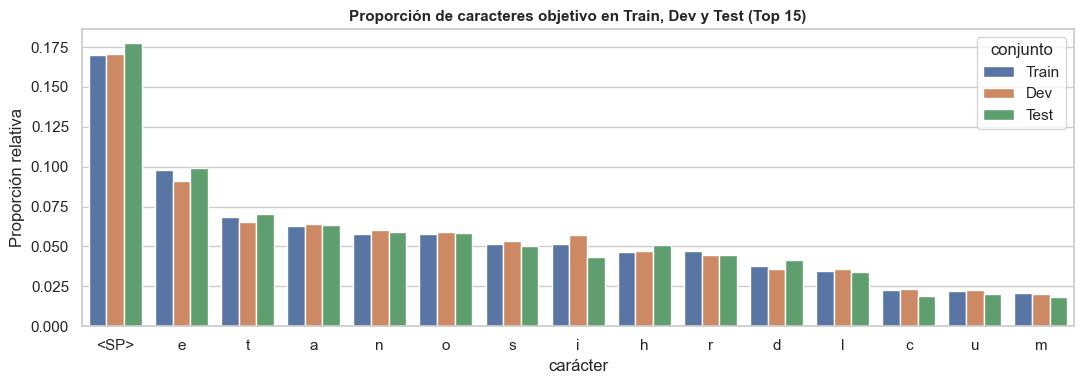

JSD(Train, Dev)  = 0.0031
JSD(Train, Test) = 0.0056
Caracteres presentes en Dev/Test y ausentes en Train: ['—']


In [ ]:

prop = (freq / freq.sum())

top15 = serie.index[:15]
df_p = prop.loc[top15].reset_index(names="carácter").melt(id_vars="carácter", var_name="conjunto", value_name="proporción")
df_p["carácter"] = df_p["carácter"].map(vis)
plt.figure(figsize=(11, 4))
sns.barplot(data=df_p, x="carácter", y="proporción", hue="conjunto")
plt.title("Proporción de caracteres objetivo en Train, Dev y Test (Top 15)", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout(); plt.show()

print(f"JSD(Train, Dev)  = {jsd(prop['Train'].values, prop['Dev'].values):.4f}")
print(f"JSD(Train, Test) = {jsd(prop['Train'].values, prop['Test'].values):.4f}")
sin_train = [vis(c) for c in vocabulary if freq.loc[c, "Train"] == 0 and (freq.loc[c, "Dev"] + freq.loc[c, "Test"]) > 0]
print(f"Caracteres presentes en Dev/Test y ausentes en Train: {sin_train}")

---
# 3. Consigna 4.1.3: Preprocesamiento y modelo baseline

## 3.1 Codificación numérica y persistencia de particiones
Guardamos los cuentos limpios y la partición (cuentos de Test, límites de bloques y bloques de Train/Dev) en `data/processed_multi/`, así todas las etapas usan exactamente los mismos datos.

In [ ]:
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

(OUT_DIR / "cuentos_limpios").mkdir(exist_ok=True)
for n, t in stories.items():
    (OUT_DIR / "cuentos_limpios" / f"{n}.txt").write_text(t, encoding="utf-8")

with open(OUT_DIR / "splits_multicuento.json", "w", encoding="utf-8") as f:
    json.dump({"L": L, "BLOQUE": BLOQUE, "SEED": SEED, "FRAC_DEV": FRAC_DEV,
               "cuentos_test": test_names, "cuentos_train_dev": trdev_names,
               "limites_bloques": limites, "bloques": bloques,
               "vocabulario": "".join(vocabulary)}, f, ensure_ascii=False)
print(f"Vocabulario (|V| = {V}), cuentos limpios y particiones guardados en {OUT_DIR.relative_to(BASE_DIR)}/")

Vocabulario (|V| = 80), cuentos limpios y particiones guardados en data\processed_multi/


## 3.2 Métricas y referencia trivial
- **Métrica de número único (consigna): accuracy top-1 en Dev.** Es fácil de interpretar y se compara con la referencia trivial de predecir siempre el carácter más frecuente **de Train**.
- **Complemento: perplejidad en Dev** (exponencial de la entropía cruzada media). Para un generador es la medida más cercana a la calidad del muestreo, porque mide qué tan bien repartida está la probabilidad y no solo cuál es el carácter más probable.
- **Piso de probabilidad:** a toda probabilidad se le aplica `max(p, 1e-6)`. Se usa el mismo piso en todos los modelos para que la perplejidad sea comparable (por ejemplo, cuando un carácter de Dev no existe en Train).

In [ ]:
clase_mayoritaria = Counter(y_train).most_common(1)[0][0]
acc_dummy_dev = float(np.mean([y == clase_mayoritaria for y in y_dev]))
print(f"Clase mayoritaria en Train: '{vis(clase_mayoritaria)}'")
print(f"Accuracy de referencia trivial en Dev: {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")

Clase mayoritaria en Train: '<SP>'
Accuracy de referencia trivial en Dev: 0.1704 (17.04%)


## 3.3 Baseline: regresión logística sobre los últimos $K$ caracteres
1. Tomamos los últimos $K$ caracteres de la ventana.
2. Los codificamos con `OneHotEncoder`.
3. Entrenamos una `LogisticRegression` multinomial (equivale a una red de una capa densa con softmax).

Probamos $K \in \{1, 3, 5, 7, 10\}$ y elegimos el mejor según la accuracy en Dev. En la versión de un solo cuento, $K = 5$ quedó en el borde de la grilla; con más datos un contexto mayor puede tener sentido.

    Accuracy Train  Accuracy Dev  Perplejidad Dev  Tiempo (s)
K                                                            
1           0.2808        0.2698          11.6011     31.4489
3           0.3727        0.3654           9.0624     37.8413
5           0.3939        0.3770           8.7683     43.1156
7           0.4087        0.3844           8.7076     55.0810
10          0.4180        0.3758           8.8525     61.2003

Mejor K según accuracy en Dev: K = 7  |  ¿En el borde de la grilla? False


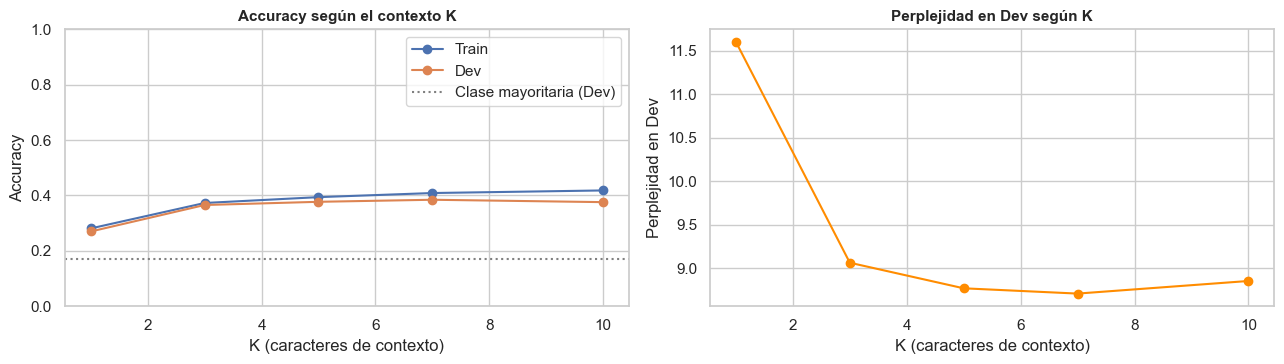

In [ ]:
def ultimos(X, k):
    return np.array([list(x[-k:]) for x in X])

def proba_completa(pipe, X_k):
    """Matriz (n, |V|) en el orden de char2idx, con ceros para clases que el modelo no vio."""
    p = pipe.predict_proba(X_k)
    out = np.zeros((len(X_k), V))
    for j, c in enumerate(pipe.classes_):
        out[:, char2idx[c]] = p[:, j]
    return out

def perdida_log(P, y_real):
    idx = np.array([char2idx[c] for c in y_real])
    return float(-np.mean(np.log(np.clip(P[np.arange(len(idx)), idx], EPS, 1.0))))

resultados_k, modelos_k, tiempos_k = [], {}, {}
for k in [1, 3, 5, 7, 10]:
    pipe = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")),
                     ("clf", LogisticRegression(max_iter=500, random_state=SEED))])
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(ultimos(X_train, k), y_train)
    tiempos_k[k] = time.perf_counter() - t0
    modelos_k[k] = pipe
    acc_tr = accuracy_score(y_train, pipe.predict(ultimos(X_train, k)))
    Xd = ultimos(X_dev, k)
    acc_dev = accuracy_score(y_dev, pipe.predict(Xd))
    perp_dev = float(np.exp(perdida_log(proba_completa(pipe, Xd), y_dev)))
    resultados_k.append({"K": k, "Accuracy Train": acc_tr, "Accuracy Dev": acc_dev,
                         "Perplejidad Dev": perp_dev, "Tiempo (s)": tiempos_k[k]})

df_k = pd.DataFrame(resultados_k).set_index("K")
print(df_k.round(4))
K_OPTIMO = int(df_k["Accuracy Dev"].idxmax())
print(f"\nMejor K según accuracy en Dev: K = {K_OPTIMO}  |  ¿En el borde de la grilla? {K_OPTIMO in (1, 10)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(df_k.index, df_k["Accuracy Train"], marker="o", label="Train")
axes[0].plot(df_k.index, df_k["Accuracy Dev"], marker="o", label="Dev")
axes[0].axhline(acc_dummy_dev, color="gray", linestyle=":", label="Clase mayoritaria (Dev)")
axes[0].set_ylim(0, 1); axes[0].set_xlabel("K (caracteres de contexto)"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy según el contexto K", fontsize=11, fontweight="bold"); axes[0].legend()
axes[1].plot(df_k.index, df_k["Perplejidad Dev"], marker="o", color="darkorange")
axes[1].set_xlabel("K (caracteres de contexto)"); axes[1].set_ylabel("Perplejidad en Dev")
axes[1].set_title("Perplejidad en Dev según K", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 3.4 Resultado oficial del baseline en Dev
Es la referencia que tienen que superar los modelos de las etapas siguientes. También se guardan la accuracy en Train, la pérdida, la perplejidad, los parámetros y el tiempo de entrenamiento (se usan en la Etapa 2 y en la tabla final de la Etapa 5).

In [ ]:
baseline_final = modelos_k[K_OPTIMO]
Xdev_opt = ultimos(X_dev, K_OPTIMO)
y_pred_dev = baseline_final.predict(Xdev_opt)

acc_base_dev = accuracy_score(y_dev, y_pred_dev)
acc_base_train = accuracy_score(y_train, baseline_final.predict(ultimos(X_train, K_OPTIMO)))
loss_base_dev = perdida_log(proba_completa(baseline_final, Xdev_opt), y_dev)
perp_base_dev = float(np.exp(loss_base_dev))
clf_base = baseline_final.named_steps["clf"]
params_base = int(clf_base.coef_.size + clf_base.intercept_.size)
tiempo_base = tiempos_k[K_OPTIMO]

print("=" * 70)
print(f"BASELINE OFICIAL — One-Hot últimos {K_OPTIMO} caracteres + Regresión Logística:")
print(f"  • Accuracy en Dev: {acc_base_dev:.4f} ({acc_base_dev*100:.2f}%)")
print(f"  • Referencia trivial (clase mayoritaria de Train): {acc_dummy_dev*100:.2f}%  ->  ganancia +{(acc_base_dev-acc_dummy_dev)*100:.2f} pp")
print(f"  • Accuracy en Train: {acc_base_train*100:.2f}% (brecha Train - Dev: {(acc_base_train-acc_base_dev)*100:.2f} pp)")
print(f"  • Pérdida en Dev: {loss_base_dev:.4f} | Perplejidad en Dev: {perp_base_dev:.2f}")
print(f"  • Muestras en Dev: {len(y_dev):,} | Parámetros: {params_base:,} | Tiempo de entrenamiento: {tiempo_base:.2f} s")
print("=" * 70)

# Accuracy por cuento en Dev (control: ¿el baseline anda parecido en todos los cuentos?)
df_dev = pd.DataFrame({"cuento": s_dev, "ok": np.array(y_dev) == np.array(y_pred_dev)})
print("\nAccuracy en Dev por cuento:")
print(df_dev.groupby("cuento")["ok"].agg(["mean", "size"]).rename(columns={"mean": "Accuracy", "size": "Muestras"}).round(4).to_string())

with open(OUT_DIR / "baseline_dev.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": f"OneHot_ultimos_{K_OPTIMO}_chars + LogisticRegression", "K": K_OPTIMO,
               "metrica_principal": "accuracy_dev", "accuracy_dev": float(acc_base_dev),
               "accuracy_train": float(acc_base_train), "loss_dev": loss_base_dev,
               "perplejidad_dev": perp_base_dev, "piso_probabilidad": EPS,
               "parametros_entrenables": params_base, "tiempo_entrenamiento_s": tiempo_base,
               "accuracy_dummy_dev": acc_dummy_dev, "n_dev": len(y_dev), "n_train": len(y_train),
               "cuentos_test": test_names}, f, indent=2, ensure_ascii=False)
print(f"\nMétrica oficial guardada en {OUT_DIR.relative_to(BASE_DIR)}/baseline_dev.json")

BASELINE OFICIAL — One-Hot últimos 7 caracteres + Regresión Logística:
  • Accuracy en Dev: 0.3844 (38.44%)
  • Referencia trivial (clase mayoritaria de Train): 17.04%  ->  ganancia +21.40 pp
  • Accuracy en Train: 40.87% (brecha Train - Dev: 2.43 pp)
  • Pérdida en Dev: 2.1642 | Perplejidad en Dev: 8.71
  • Muestras en Dev: 6,480 | Parámetros: 43,766 | Tiempo de entrenamiento: 55.08 s

Accuracy en Dev por cuento:
                    Accuracy  Muestras
cuento                                
The callof cthulhu    0.3844      6480

Métrica oficial guardada en data\processed_multi/baseline_dev.json


## 3.5 Matriz de confusión y errores más frecuentes del baseline
Matriz de confusión normalizada de las 20 clases más frecuentes en Dev, y los pares real → predicho más repetidos.

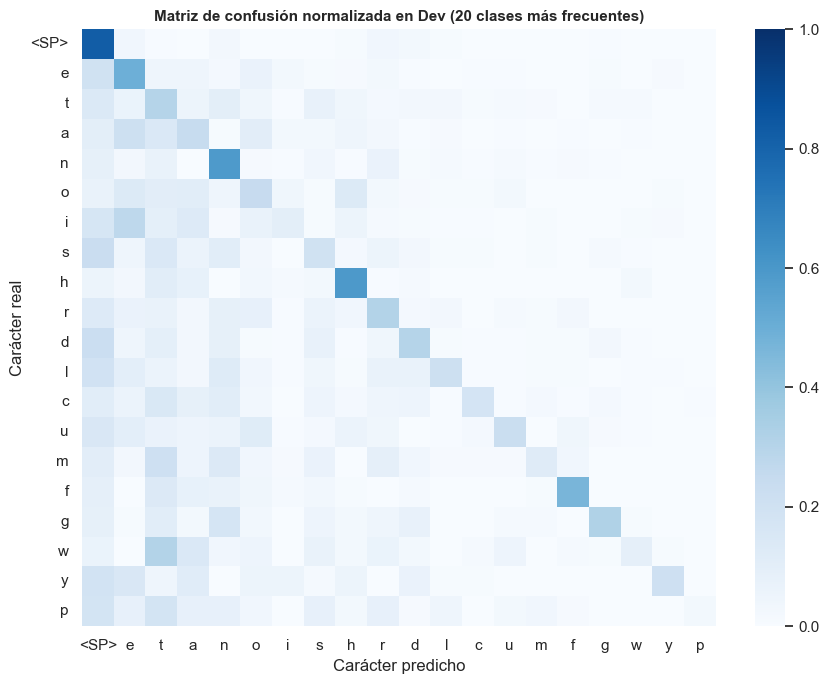

Total de errores en Dev: 3,989 de 6,480

Pares más confundidos (real -> predicho):
Real Predicho  Ocurrencias
   e     <SP>          116
   i        e          102
   a        e           89
   s     <SP>           80
   i     <SP>           62
   t     <SP>           61
   a        t           60
   d     <SP>           53


In [ ]:
labels_all = sorted(set(y_dev) | set(y_pred_dev))
cm = confusion_matrix(y_dev, y_pred_dev, labels=labels_all, normalize="true")
top20 = [c for c, _ in Counter(y_dev).most_common(20)]
ix = [labels_all.index(c) for c in top20]

plt.figure(figsize=(9, 7))
sns.heatmap(cm[np.ix_(ix, ix)], cmap="Blues", vmin=0, vmax=1,
            xticklabels=[vis(c) for c in top20], yticklabels=[vis(c) for c in top20])
plt.title("Matriz de confusión normalizada en Dev (20 clases más frecuentes)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter predicho"); plt.ylabel("Carácter real"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

errores = [(r, p) for r, p in zip(y_dev, y_pred_dev) if r != p]
print(f"Total de errores en Dev: {len(errores):,} de {len(y_dev):,}")
df_err = pd.DataFrame([(vis(r), vis(p), n) for (r, p), n in Counter(errores).most_common(8)],
                      columns=["Real", "Predicho", "Ocurrencias"])
print("\nPares más confundidos (real -> predicho):")
print(df_err.to_string(index=False))

---
# 4. Síntesis y checklist de la Etapa 1

In [ ]:
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 1 (versión multi-cuento)")
print(f"  [x] 4.1.1 Carga y EDA: {len(stories)} cuentos, {len(corpus_total):,} caracteres, |V| = {vocab_size}, "
      f"5 gráficos descriptivos y diagnóstico de desbalance, clases raras y data mismatch (JSD).")
print(f"  [x] 4.1.2 Partición: Train ({len(X_train):,}) / Dev ({len(X_dev):,}) por bloques de todos los cuentos; "
      f"Test ({len(X_test):,}) = cuentos completos reservados {test_names}.")
print("  [x] 4.1.2 Auditoría: cada cuento en Train y Dev; sin cuentos de Test en Train/Dev; sin texto repetido evidente con Test.")
print("  [x] 4.1.2 Proporciones de clases verificadas en los tres conjuntos.")
print(f"  [x] 4.1.3 Baseline: One-Hot de los últimos {K_OPTIMO} caracteres + Regresión Logística multinomial.")
print(f"  [x] 4.1.3 Métrica de número único: accuracy en Dev = {acc_base_dev:.4f} (trivial = {acc_dummy_dev:.4f}); perplejidad en Dev = {perp_base_dev:.2f}.")
print(f"  [x] Particiones, cuentos limpios y baseline guardados en {OUT_DIR.relative_to(BASE_DIR)}/.")
print("  [x] Test intacto: solo se contaron clases; ningún modelo se evaluó sobre él.")

CHECKLIST DE CUMPLIMIENTO - ETAPA 1 (versión multi-cuento)
  [x] 4.1.1 Carga y EDA: 2 cuentos, 90,084 caracteres, |V| = 80, 5 gráficos descriptivos y diagnóstico de desbalance, clases raras y data mismatch (JSD).
  [x] 4.1.2 Partición: Train (56,424) / Dev (6,480) por bloques de todos los cuentos; Test (20,140) = cuentos completos reservados ['The_Festival'].
  [x] 4.1.2 Auditoría: cada cuento en Train y Dev; sin cuentos de Test en Train/Dev; sin texto repetido evidente con Test.
  [x] 4.1.2 Proporciones de clases verificadas en los tres conjuntos.
  [x] 4.1.3 Baseline: One-Hot de los últimos 7 caracteres + Regresión Logística multinomial.
  [x] 4.1.3 Métrica de número único: accuracy en Dev = 0.3844 (trivial = 0.1704); perplejidad en Dev = 8.71.
  [x] Particiones, cuentos limpios y baseline guardados en data\processed_multi/.
  [x] Test intacto: solo se contaron clases; ningún modelo se evaluó sobre él.
